# ViVQA Evaluation
Notebook riêng để chạy đánh giá Teacher/Student từ checkpoint, không dùng chung với demo.

In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True, timeout_ms=600000)

Mounted at /content/drive


In [1]:

import torch
assert torch.cuda.is_available(), 'Hãy chọn GPU T4 trước khi chạy'
print('GPU:', torch.cuda.get_device_name(0))

Mounted at /content/drive


AssertionError: Hãy chọn GPU T4 trước khi chạy

In [ ]:
from pathlib import Path
import base64, re
PROJECT = Path('/content/drive/MyDrive/TtI/Vi-VQA-End-to-End')
script_path = PROJECT / 'scripts/evaluate_resume.py'
script_path.parent.mkdir(parents=True, exist_ok=True)
script_path.write_bytes(base64.b64decode('IyEvdXNyL2Jpbi9lbnYgcHl0aG9uMwoiIiJSdW4gcmVzdW1hYmxlIFRlYWNoZXIgb3IgU3R1ZGVudCBwcmVkaWN0aW9uIG9uIGEgZml4ZWQgVlFBIHNwbGl0LiIiIgoKaW1wb3J0IGFyZ3BhcnNlCmltcG9ydCBqc29uCmltcG9ydCB0aW1lCmZyb20gcGF0aGxpYiBpbXBvcnQgUGF0aApmcm9tIHVybGxpYi5wYXJzZSBpbXBvcnQgdXJscGFyc2UKCmltcG9ydCB0b3JjaAoKZnJvbSBzcmMuZGF0YSBpbXBvcnQgVlFBRGF0YUxvYWRlcgpmcm9tIHNyYy5tb2RlbHMgaW1wb3J0IFZRQU1vZGVsTG9hZGVyCmZyb20gc3JjLm1vZGVscy5pbmZlcmVuY2UgaW1wb3J0IFZRQUluZmVyZW5jZQpmcm9tIHNyYy5tb2RlbHMubW9kZWxfd3JhcHBlciBpbXBvcnQgU3R1ZGVudE1vZGVsLCBUZWFjaGVyTW9kZWwKCgpkZWYgcGFyc2VfYXJncygpOgogICAgcGFyc2VyID0gYXJncGFyc2UuQXJndW1lbnRQYXJzZXIoZGVzY3JpcHRpb249X19kb2NfXykKICAgIHBhcnNlci5hZGRfYXJndW1lbnQoIi0tbW9kZWwtdHlwZSIsIGNob2ljZXM9KCJ0ZWFjaGVyIiwgInN0dWRlbnQiKSwgcmVxdWlyZWQ9VHJ1ZSkKICAgIHBhcnNlci5hZGRfYXJndW1lbnQoIi0tc3BsaXQiLCBjaG9pY2VzPSgidHJhaW4iLCAiZGV2IiksIGRlZmF1bHQ9ImRldiIpCiAgICBwYXJzZXIuYWRkX2FyZ3VtZW50KCItLWltYWdlcy1kaXIiLCByZXF1aXJlZD1UcnVlKQogICAgcGFyc2VyLmFkZF9hcmd1bWVudCgiLS1vdXRwdXQtZmlsZSIsIHJlcXVpcmVkPVRydWUpCiAgICBwYXJzZXIuYWRkX2FyZ3VtZW50KCItLW1heC1uZXctdG9rZW5zIiwgdHlwZT1pbnQsIGRlZmF1bHQ9NDgpCiAgICBwYXJzZXIuYWRkX2FyZ3VtZW50KCItLWNoZWNrcG9pbnQtZXZlcnkiLCB0eXBlPWludCwgZGVmYXVsdD0yNSkKICAgIHBhcnNlci5hZGRfYXJndW1lbnQoIi0tbGltaXQiLCB0eXBlPWludCkKICAgIHBhcnNlci5hZGRfYXJndW1lbnQoIi0tcmVzdW1lIiwgYWN0aW9uPSJzdG9yZV90cnVlIikKICAgIHJldHVybiBwYXJzZXIucGFyc2VfYXJncygpCgoKZGVmIGF0b21pY19zYXZlKHBhdGgsIHBheWxvYWQpOgogICAgcGF0aC5wYXJlbnQubWtkaXIocGFyZW50cz1UcnVlLCBleGlzdF9vaz1UcnVlKQogICAgdGVtcG9yYXJ5ID0gcGF0aC53aXRoX3N1ZmZpeChwYXRoLnN1ZmZpeCArICIudG1wIikKICAgIHRlbXBvcmFyeS53cml0ZV90ZXh0KGpzb24uZHVtcHMocGF5bG9hZCwgZW5zdXJlX2FzY2lpPUZhbHNlKSwgZW5jb2Rpbmc9InV0Zi04IikKICAgIHRlbXBvcmFyeS5yZXBsYWNlKHBhdGgpCgoKZGVmIGxvYWRfaW5mZXJlbmNlKG1vZGVsX3R5cGUpOgogICAgbG9hZGVyID0gVlFBTW9kZWxMb2FkZXIoZGV2aWNlPSJjdWRhIiwgbG9hZF9pbl80Yml0PVRydWUpCiAgICBpZiBtb2RlbF90eXBlID09ICJ0ZWFjaGVyIjoKICAgICAgICBtb2RlbCwgcHJvY2Vzc29yID0gbG9hZGVyLmxvYWRfdGVhY2hlcl9tb2RlbCgpCiAgICAgICAgd3JhcHBlciA9IFRlYWNoZXJNb2RlbChtb2RlbCwgcHJvY2Vzc29yLCBkZXZpY2U9bG9hZGVyLmRldmljZSkKICAgIGVsc2U6CiAgICAgICAgbW9kZWwsIHByb2Nlc3NvciA9IGxvYWRlci5sb2FkX3N0dWRlbnRfbW9kZWwoKQogICAgICAgIHdyYXBwZXIgPSBTdHVkZW50TW9kZWwobW9kZWwsIHByb2Nlc3NvciwgZGV2aWNlPWxvYWRlci5kZXZpY2UpCiAgICByZXR1cm4gVlFBSW5mZXJlbmNlKHdyYXBwZXIpCgoKZGVmIG1haW4oKToKICAgIGFyZ3MgPSBwYXJzZV9hcmdzKCkKICAgIGlmIG5vdCB0b3JjaC5jdWRhLmlzX2F2YWlsYWJsZSgpOgogICAgICAgIHJhaXNlIFJ1bnRpbWVFcnJvcigiQ1VEQSBpcyByZXF1aXJlZCBmb3IgdGhpcyBldmFsdWF0aW9uIikKCiAgICByb3dzID0gbGlzdChWUUFEYXRhTG9hZGVyKCkuZ2V0X3NwbGl0KGFyZ3Muc3BsaXQpKQogICAgaWYgYXJncy5saW1pdCBpcyBub3QgTm9uZToKICAgICAgICByb3dzID0gcm93c1s6IGFyZ3MubGltaXRdCgogICAgaW1hZ2VzX2RpciA9IFBhdGgoYXJncy5pbWFnZXNfZGlyKQogICAgb3V0cHV0X3BhdGggPSBQYXRoKGFyZ3Mub3V0cHV0X2ZpbGUpCiAgICBwcmVkaWN0aW9ucyA9IFtdCiAgICBpZiBhcmdzLnJlc3VtZSBhbmQgb3V0cHV0X3BhdGguaXNfZmlsZSgpOgogICAgICAgIHNhdmVkID0ganNvbi5sb2FkcyhvdXRwdXRfcGF0aC5yZWFkX3RleHQoZW5jb2Rpbmc9InV0Zi04IikpCiAgICAgICAgcHJlZGljdGlvbnMgPSBzYXZlZC5nZXQoInByZWRpY3Rpb25zIiwgW10pCgogICAgc3RhcnRfaW5kZXggPSBsZW4ocHJlZGljdGlvbnMpCiAgICBpZiBzdGFydF9pbmRleCA+IGxlbihyb3dzKToKICAgICAgICByYWlzZSBWYWx1ZUVycm9yKCJDaGVja3BvaW50IGNvbnRhaW5zIG1vcmUgcHJlZGljdGlvbnMgdGhhbiB0aGUgc2VsZWN0ZWQgc3BsaXQiKQogICAgaWYgc3RhcnRfaW5kZXg6CiAgICAgICAgZXhwZWN0ZWRfaWQgPSBzdHIocm93c1tzdGFydF9pbmRleCAtIDFdWyJpZCJdKQogICAgICAgIHNhdmVkX2lkID0gc3RyKHByZWRpY3Rpb25zWy0xXS5nZXQoImlkIikpCiAgICAgICAgaWYgc2F2ZWRfaWQgIT0gZXhwZWN0ZWRfaWQ6CiAgICAgICAgICAgIHJhaXNlIFZhbHVlRXJyb3IoCiAgICAgICAgICAgICAgICBmIkNoZWNrcG9pbnQgb3JkZXIgbWlzbWF0Y2g6IGV4cGVjdGVkIGxhc3QgaWQge2V4cGVjdGVkX2lkfSwgZ290IHtzYXZlZF9pZH0iCiAgICAgICAgICAgICkKCiAgICBwcmludChmIlt7YXJncy5tb2RlbF90eXBlfV0gVGnhur9wIHThu6VjIHThu6sge3N0YXJ0X2luZGV4fS97bGVuKHJvd3MpfSIsIGZsdXNoPVRydWUpCiAgICBpbmZlcmVuY2UgPSBsb2FkX2luZmVyZW5jZShhcmdzLm1vZGVsX3R5cGUpCiAgICBzZXNzaW9uX3N0YXJ0ID0gdGltZS50aW1lKCkKCiAgICBkZWYgc2F2ZSgpOgogICAgICAgIGF0b21pY19zYXZlKAogICAgICAgICAgICBvdXRwdXRfcGF0aCwKICAgICAgICAgICAgewogICAgICAgICAgICAgICAgIm1vZGVsIjogYXJncy5tb2RlbF90eXBlLAogICAgICAgICAgICAgICAgInNwbGl0IjogYXJncy5zcGxpdCwKICAgICAgICAgICAgICAgICJjb21wbGV0ZWQiOiBsZW4ocHJlZGljdGlvbnMpLAogICAgICAgICAgICAgICAgInRvdGFsIjogbGVuKHJvd3MpLAogICAgICAgICAgICAgICAgIm1heF9uZXdfdG9rZW5zIjogYXJncy5tYXhfbmV3X3Rva2VucywKICAgICAgICAgICAgICAgICJwcmVkaWN0aW9ucyI6IHByZWRpY3Rpb25zLAogICAgICAgICkKCiAgICBmb3IgaW5kZXggaW4gcmFuZ2Uoc3RhcnRfaW5kZXgsIGxlbihyb3dzKSk6CiAgICAgICAgcm93ID0gcm93c1tpbmRleF0KICAgICAgICBpbWFnZV9uYW1lID0gUGF0aCh1cmxwYXJzZShyb3dbImltYWdlIl0pLnBhdGgpLm5hbWUKICAgICAgICBpbWFnZV9wYXRoID0gaW1hZ2VzX2RpciAvIGltYWdlX25hbWUKICAgICAgICBpZiBub3QgaW1hZ2VfcGF0aC5pc19maWxlKCk6CiAgICAgICAgICAgIHJhaXNlIEZpbGVOb3RGb3VuZEVycm9yKGYiTWlzc2luZyBpbWFnZToge2ltYWdlX3BhdGh9IikKCiAgICAgICAgc3RhcnRlZCA9IHRpbWUucGVyZl9jb3VudGVyKCkKICAgICAgICBhbnN3ZXIgPSBpbmZlcmVuY2UucHJlZGljdF9zaW5nbGUoCiAgICAgICAgICAgIHN0cihpbWFnZV9wYXRoKSwgcm93WyJxdWVzdGlvbiJdLCBhcmdzLm1heF9uZXdfdG9rZW5zCiAgICAgICAgKQogICAgICAgIGxhdGVuY3kgPSB0aW1lLnBlcmZfY291bnRlcigpIC0gc3RhcnRlZAogICAgICAgIHByZWRpY3Rpb25zLmFwcGVuZCgKICAgICAgICAgICAgewogICAgICAgICAgICAgICAgImlkIjogc3RyKHJvd1siaWQiXSksCiAgICAgICAgICAgICAgICAiaW1hZ2VfcGF0aCI6IHN0cihpbWFnZV9wYXRoKSwKICAgICAgICAgICAgICAgICJxdWVzdGlvbiI6IHJvd1sicXVlc3Rpb24iXSwKICAgICAgICAgICAgICAgICJwcmVkaWN0ZWRfYW5zd2VyIjogYW5zd2VyLAogICAgICAgICAgICAgICAgInJlZmVyZW5jZV9hbnN3ZXIiOiByb3dbImFuc3dlciJdLAogICAgICAgICAgICAgICAgImxhdGVuY3lfcyI6IGxhdGVuY3ksCiAgICAgICAgICAgIH0KICAgICAgICApCgogICAgICAgIGNvbXBsZXRlZCA9IGluZGV4ICsgMQogICAgICAgIGlmIGNvbXBsZXRlZCAlIGFyZ3MuY2hlY2twb2ludF9ldmVyeSA9PSAwIG9yIGNvbXBsZXRlZCA9PSBsZW4ocm93cyk6CiAgICAgICAgICAgIHNhdmUoKQogICAgICAgICAgICBlbGFwc2VkX21pbnV0ZXMgPSAodGltZS50aW1lKCkgLSBzZXNzaW9uX3N0YXJ0KSAvIDYwCiAgICAgICAgICAgIHByaW50KAogICAgICAgICAgICAgICAgZiJbe2FyZ3MubW9kZWxfdHlwZX1dIHtjb21wbGV0ZWR9L3tsZW4ocm93cyl9IHwgIgogICAgICAgICAgICAgICAgZiJwaGnDqm4gbsOgeSB7ZWxhcHNlZF9taW51dGVzOi4xZn0gcGjDunQiLAogICAgICAgICAgICAgICAgZmx1c2g9VHJ1ZSwKICAgICAgICAgICAgKQoKICAgIHNhdmUoKQogICAgcHJpbnQoZiJbe2FyZ3MubW9kZWxfdHlwZX1dIEhvw6BuIHThuqV0OiB7b3V0cHV0X3BhdGh9IiwgZmx1c2g9VHJ1ZSkKCgppZiBfX25hbWVfXyA9PSAiX19tYWluX18iOgogICAgbWFpbigpCg=='))
loader = PROJECT / 'src/data/data_loader.py'
text = loader.read_text(encoding='utf-8')
text = re.sub(r'repo_id: str = "[^"]+/vlsp2023-vqa-dataset"', 'repo_id: str = "Ouyangxuelili/vlsp2023-vqa-dataset"', text)
loader.write_text(text, encoding='utf-8')
print('Đã cập nhật:', script_path)
print('Nguồn dữ liệu:', 'Ouyangxuelili/vlsp2023-vqa-dataset')

Đã cập nhật: /content/drive/MyDrive/TtI/Vi-VQA-End-to-End/scripts/evaluate_resume.py
Nguồn dữ liệu: Ouyangxuelili/vlsp2023-vqa-dataset


In [ ]:
from pathlib import Path
p = PROJECT / 'scripts/evaluate_resume.py'
lines = p.read_text(encoding='utf-8').splitlines()
lines[89] = '            },'
lines[90] = '        )'
text = '\n'.join(lines) + '\n'
marker = "sys.path.insert(0, str(Path(__file__).resolve().parents[1]))"
if marker not in text:
    text = text.replace('from pathlib import Path\n', 'from pathlib import Path\nimport sys\n' + marker + '\n', 1)
compile(text, str(p), 'exec')
p.write_text(text, encoding='utf-8')
print('Script evaluation đã sẵn sàng')

In [ ]:
from pathlib import Path
import os, shutil
DRIVE_PROJECT = Path('/content/drive/MyDrive/TtI/Vi-VQA-End-to-End')
LOCAL_PROJECT = Path('/content/Vi-VQA-End-to-End')
assert DRIVE_PROJECT.is_dir(), f'Không tìm thấy {DRIVE_PROJECT}'
os.chdir('/content')
if LOCAL_PROJECT.is_symlink(): LOCAL_PROJECT.unlink()
elif LOCAL_PROJECT.exists(): shutil.rmtree(LOCAL_PROJECT)
LOCAL_PROJECT.mkdir(parents=True)
for name in ['requirements-app.txt', 'requirements.txt', 'src', 'scripts']:
    source, target = DRIVE_PROJECT / name, LOCAL_PROJECT / name
    shutil.copytree(source, target) if source.is_dir() else shutil.copy2(source, target)
for relative in ['outputs-7B/final_lora', 'outputs-2B-distilled/final_lora']:
    source, target = DRIVE_PROJECT / relative, LOCAL_PROJECT / relative
    target.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(source, target)
(LOCAL_PROJECT / 'models').symlink_to(DRIVE_PROJECT / 'models', target_is_directory=True)
print('Project:', LOCAL_PROJECT)

Project: /content/Vi-VQA-End-to-End


In [ ]:
%cd /content/Vi-VQA-End-to-End
!pip install -q -r requirements-app.txt rouge-score bert-score

/content/Vi-VQA-End-to-End
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 80.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 557.0/557.0 kB 31.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 MB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.3/32.3 MB 27.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 45.9 MB/s eta 0:00:00


In [ ]:
from huggingface_hub import hf_hub_download
import zipfile
images_root = Path('/content/openvivqa-dev/images')
dev_images = images_root / 'dev-images'
if len(list(dev_images.glob('*.jpg'))) < 572:
    archive = hf_hub_download(repo_id='uitnlp/OpenViVQA-dataset', repo_type='dataset', filename='dev-images.zip', cache_dir='/content/hf-cache')
    images_root.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as zf: zf.extractall(images_root)
print('Dev images:', len(list(dev_images.glob('*.jpg'))))

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


dev-images.zip:   0%|          | 0.00/165M [00:00<?, ?B/s]

Dev images: 1070


In [ ]:
import json
checkpoint = DRIVE_PROJECT / 'results/teacher_dev_3545.partial.json'
saved = json.loads(checkpoint.read_text(encoding='utf-8'))
print(f"Teacher checkpoint: {saved['completed']}/{saved['total']}")

Teacher checkpoint: 325/3545


In [ ]:
!python -u scripts/evaluate_resume.py \
  --model-type teacher \
  --split dev \
  --images-dir /content/openvivqa-dev/images/dev-images \
  --output-file /content/drive/MyDrive/TtI/Vi-VQA-End-to-End/results/teacher_dev_3545.partial.json \
  --max-new-tokens 48 \
  --checkpoint-every 25 \
  --resume

2026-08-14 15:27:50.694849: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
vlsp2023_train_data.json: 6.60MB [00:00, 34.8MB/s]
vlsp2023_dev_data.json: 762kB [00:00, 29.9MB/s]
Dataset loaded: Ouyangxuelili/vlsp2023-vqa-dataset
  - train: 30833 samples
  - dev: 3545 samples
[teacher] Tiếp tục từ 325/3545
Loading processor from: /content/Vi-VQA-End-to-End/outputs-7B/final_lora
Loading base model: /content/Vi-VQA-End-to-End/models/Qwen2-VL-7B-Instruct
Loading checkpoint shards: 100% 5/5 [05:12<00:00, 62.51s/it]
Attaching LoRA adapter: /content/Vi-VQA-End-to-End/outputs-7B/final_lora
/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:2919: UserWarning: `max_length` is ignored when `padding`=`True` and there is no truncatio

In [ ]:
from pathlib import Path
paths = [Path('/content/drive/MyDrive/TtI/Vi-VQA-End-to-End/scripts/evaluate_resume.py'), Path('/content/Vi-VQA-End-to-End/scripts/evaluate_resume.py')]
for p in paths:
    text = p.read_text(encoding='utf-8')
    marker = "sys.path.insert(0, str(Path(__file__).resolve().parents[1]))"
    if marker not in text:
        text = text.replace('from pathlib import Path\n', 'from pathlib import Path\nimport sys\n' + marker + '\n', 1)
    compile(text, str(p), 'exec')
    p.write_text(text, encoding='utf-8')
    print('Đã sửa import:', p)

Đã sửa import: /content/drive/MyDrive/TtI/Vi-VQA-End-to-End/scripts/evaluate_resume.py
Đã sửa import: /content/Vi-VQA-End-to-End/scripts/evaluate_resume.py


In [ ]:
%pip install -q -U bitsandbytes accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 MB 31.4 MB/s eta 0:00:00


In [ ]:
import os
import sys
from pathlib import Path

DRIVE_PROJECT = Path(
    "/content/drive/MyDrive/TtI/Vi-VQA-End-to-End"
)

assert DRIVE_PROJECT.exists(), DRIVE_PROJECT

sys.path.insert(0, str(DRIVE_PROJECT))
os.chdir(DRIVE_PROJECT)

print("Đang chạy tại:", os.getcwd())
print("src tồn tại:", (DRIVE_PROJECT / "src").exists())

Đang chạy tại: /content/drive/.shortcut-targets-by-id/1ppKPJjB97K9rw1WQmrsYkA-E3348PRGD/TtI/Vi-VQA-End-to-End
src tồn tại: True


In [ ]:
from pathlib import Path
from huggingface_hub import hf_hub_download
import zipfile

IMAGES_ROOT = Path("/content/openvivqa-dev/images")
IMAGES_DIR = IMAGES_ROOT / "dev-images"

archive = hf_hub_download(
    repo_id="uitnlp/OpenViVQA-dataset",
    repo_type="dataset",
    filename="dev-images.zip",
    cache_dir="/content/hf-cache",
)

IMAGES_ROOT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(archive) as zf:
    zf.extractall(IMAGES_ROOT)

print("Đã tải ảnh:", len(list(IMAGES_DIR.glob("*.jpg"))))

dev-images.zip: reconstructing file:   0%|          |  0.00B /  165MB            

dev-images.zip: downloading bytes:           |  0.00B            

Đã tải ảnh: 1070


In [ ]:
from pathlib import Path
import json

p = Path(
    "/content/drive/MyDrive/TtI/Vi-VQA-End-to-End/"
    "results/baseline2b_dev_3545.partial.json"
)

if p.exists():
    data = json.loads(p.read_text(encoding="utf-8"))
    print(data["completed"], "/", data["total"])
else:
    print("Chưa có checkpoint, sẽ chạy từ đầu.")

2575 / 3545


In [ ]:
import os
import sys
import gc
import json
import time
from pathlib import Path
from urllib.parse import urlparse

import torch
from PIL import Image

from src.data import VQADataLoader
from src.models import VQAModelLoader
from src.models.model_wrapper import VisionLanguageModelWrapper

DRIVE_PROJECT = Path(
    "/content/drive/MyDrive/TtI/Vi-VQA-End-to-End"
)

IMAGES_DIR = Path(
    "/content/openvivqa-dev/images/dev-images"
)

assert DRIVE_PROJECT.exists(), f"Không tìm thấy: {DRIVE_PROJECT}"
assert IMAGES_DIR.exists(), f"Không tìm thấy: {IMAGES_DIR}"
assert torch.cuda.is_available(), "Colab chưa bật GPU"

sys.path.insert(0, str(DRIVE_PROJECT))
os.chdir(DRIVE_PROJECT)

print("GPU:", torch.cuda.get_device_name(0))
print("Project:", DRIVE_PROJECT)
print("Số ảnh:", len(list(IMAGES_DIR.glob("*.jpg"))))

for name in [
    "model",
    "processor",
    "wrapper",
    "loader",
    "predictions",
]:
    globals().pop(name, None)

gc.collect()
torch.cuda.empty_cache()

rows = list(VQADataLoader().get_split("dev"))
print("Số mẫu đánh giá:", len(rows))

assert len(rows) == 3545

missing = []

for row in rows:
    image_name = Path(urlparse(row["image"]).path).name
    image_path = IMAGES_DIR / image_name

    if not image_path.is_file():
        missing.append(str(image_path))

if missing:
    print("Một số ảnh bị thiếu:")
    print(*missing[:5], sep="\n")
    raise FileNotFoundError(
        f"Thiếu tổng cộng {len(missing)} ảnh. "
        "Hãy chạy lại cell tải dev-images."
    )

print("Đã kiểm tra đủ ảnh.")

RESULT_FILE = (
    DRIVE_PROJECT
    / "results"
    / "baseline2b_dev_3545.partial.json"
)

RESULT_FILE.parent.mkdir(parents=True, exist_ok=True)

predictions = []

if RESULT_FILE.exists():
    saved = json.loads(
        RESULT_FILE.read_text(encoding="utf-8")
    )

    predictions = saved.get("predictions", [])

    print(
        f"Tiếp tục từ "
        f"{len(predictions)}/{len(rows)} mẫu"
    )

if len(predictions) > len(rows):
    raise ValueError(
        "Checkpoint có nhiều mẫu hơn tập dev hiện tại."
    )

loader = VQAModelLoader(
    device="cuda",
    load_in_4bit=True,
)

model, processor = loader.load_model(
    "Qwen/Qwen2-VL-2B-Instruct",
    load_in_4bit=True,
)

processor.image_processor.min_pixels = 200704
processor.image_processor.max_pixels = 401408

wrapper = VisionLanguageModelWrapper(
    model,
    processor,
    "Base 2B chưa fine-tune",
    device=loader.device,
)

print("Đã nạp Base 2B với giới hạn ảnh an toàn.")

def predict_baseline(image_path, question):
    image = Image.open(image_path).convert("RGB")

    image.thumbnail(
        (1024, 1024),
        Image.Resampling.LANCZOS
    )

    return wrapper.answer_question(
        image,
        question,
        max_new_tokens=48,
    )

def save_checkpoint():
    payload = {
        "model": "baseline2b",
        "split": "dev",
        "completed": len(predictions),
        "total": len(rows),
        "max_new_tokens": 48,
        "predictions": predictions,
    }

    temporary = RESULT_FILE.with_name(
        RESULT_FILE.name + ".tmp"
    )

    temporary.write_text(
        json.dumps(
            payload,
            ensure_ascii=False
        ),
        encoding="utf-8",
    )

    temporary.replace(RESULT_FILE)

for index in range(len(predictions), len(rows)):
    row = rows[index]

    image_name = Path(
        urlparse(row["image"]).path
    ).name

    image_path = IMAGES_DIR / image_name

    started = time.perf_counter()

    answer = predict_baseline(
        image_path,
        row["question"],
    )

    predictions.append(
        {
            "id": str(row["id"]),
            "image_path": str(image_path),
            "question": row["question"],
            "predicted_answer": answer,
            "reference_answer": row["answer"],
            "latency_s": (
                time.perf_counter() - started
            ),
        }
    )

    completed = index + 1

    if (
        completed % 25 == 0
        or completed == len(rows)
    ):
        save_checkpoint()

        print(
            f"[baseline2b] "
            f"{completed}/{len(rows)}",
            flush=True,
        )

save_checkpoint()

print("Đã hoàn tất Base 2B:")
print(RESULT_FILE)

GPU: Tesla T4
Project: /content/drive/MyDrive/TtI/Vi-VQA-End-to-End
Số ảnh: 1070
Dataset loaded: Ouyangxuelili/vlsp2023-vqa-dataset
  - train: 30833 samples
  - dev: 3545 samples
Số mẫu đánh giá: 3545
Đã kiểm tra đủ ảnh.
Tiếp tục từ 2575/3545 mẫu


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Đã nạp Base 2B với giới hạn ảnh an toàn.
[baseline2b] 2600/3545
[baseline2b] 2625/3545
[baseline2b] 2650/3545
[baseline2b] 2675/3545
[baseline2b] 2700/3545
[baseline2b] 2725/3545
[baseline2b] 2750/3545
[baseline2b] 2775/3545
[baseline2b] 2800/3545
[baseline2b] 2825/3545
[baseline2b] 2850/3545
[baseline2b] 2875/3545
[baseline2b] 2900/3545
[baseline2b] 2925/3545
[baseline2b] 2950/3545
[baseline2b] 2975/3545
[baseline2b] 3000/3545
[baseline2b] 3025/3545
[baseline2b] 3050/3545
[baseline2b] 3075/3545
[baseline2b] 3100/3545
[baseline2b] 3125/3545
[baseline2b] 3150/3545
[baseline2b] 3175/3545
[baseline2b] 3200/3545
[baseline2b] 3225/3545
[baseline2b] 3250/3545
[baseline2b] 3275/3545
[baseline2b] 3300/3545
[baseline2b] 3325/3545
[baseline2b] 3350/3545
[baseline2b] 3375/3545
[baseline2b] 3400/3545
[baseline2b] 3425/3545
[baseline2b] 3450/3545
[baseline2b] 3475/3545
[baseline2b] 3500/3545
[baseline2b] 3525/3545
[baseline2b] 3545/3545
Đã hoàn tất Base 2B:
/content/drive/MyDrive/TtI/Vi-VQA-End-to-

In [ ]:
from src.training import MetricsCalculator
result = json.loads(checkpoint.read_text(encoding='utf-8'))
assert result['completed'] == result['total'], 'Teacher chưa chạy xong'
predictions = [x['predicted_answer'] for x in result['predictions']]
references = [x['reference_answer'] for x in result['predictions']]
metrics = MetricsCalculator.calculate_all_metrics(predictions, references)
metrics_path = DRIVE_PROJECT / 'results/teacher_dev_3545.metrics.json'
metrics_path.write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
metrics

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

{'exact_match': 0.19520451339915373,
 'rouge_l': np.float64(0.6538061010568075),
 'bertscore_f1': 0.8727375864982605}

In [ ]:
import os
import sys
from pathlib import Path

DRIVE_PROJECT = Path(
    "/content/drive/MyDrive/TtI/Vi-VQA-End-to-End"
)

assert DRIVE_PROJECT.exists(), DRIVE_PROJECT

sys.path.insert(0, str(DRIVE_PROJECT))
os.chdir(DRIVE_PROJECT)

print("Đang chạy tại:", os.getcwd())

Đang chạy tại: /content/drive/MyDrive/TtI/Vi-VQA-End-to-End


In [ ]:
%pip install -q rouge-score bert-score

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.5 MB/s eta 0:00:00


In [ ]:
import json
import pandas as pd
from src.training import MetricsCalculator

def calculate_metrics(filename, output_name, label):
    path = DRIVE_PROJECT / "results" / filename
    result = json.loads(path.read_text(encoding="utf-8"))

    print(label, result["completed"], "/", result["total"])
    assert result["completed"] == result["total"] == 3545

    predictions = [
        x["predicted_answer"]
        for x in result["predictions"]
    ]

    references = [
        x["reference_answer"]
        for x in result["predictions"]
    ]

    metrics = MetricsCalculator.calculate_all_metrics(
        predictions,
        references,
    )

    output_path = (
        DRIVE_PROJECT
        / "results"
        / f"{output_name}_dev_3545.metrics.json"
    )

    output_path.write_text(
        json.dumps(
            metrics,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )

    return metrics


teacher_metrics = calculate_metrics(
    "teacher_dev_3545.partial.json",
    "teacher",
    "Teacher 7B",
)

student_metrics = calculate_metrics(
    "student_dev_3545.partial.json",
    "student",
    "Student 2B sau KD",
)

baseline_metrics = calculate_metrics(
    "baseline2b_dev_3545.partial.json",
    "baseline2b",
    "Base 2B chưa fine-tune",
)


table = pd.DataFrame([
    {
        "Model": "Base 2B",
        "Exact Match": baseline_metrics["exact_match"],
        "ROUGE-L": baseline_metrics["rouge_l"],
        "BERTScore F1": baseline_metrics["bertscore_f1"],
    },
    {
        "Model": "Teacher 7B",
        "Exact Match": teacher_metrics["exact_match"],
        "ROUGE-L": teacher_metrics["rouge_l"],
        "BERTScore F1": teacher_metrics["bertscore_f1"],
    },
    {
        "Model": "Student 2B sau KD",
        "Exact Match": student_metrics["exact_match"],
        "ROUGE-L": student_metrics["rouge_l"],
        "BERTScore F1": student_metrics["bertscore_f1"],
    },
])

display(
    table.style.format({
        "Exact Match": "{:.4f}",
        "ROUGE-L": "{:.4f}",
        "BERTScore F1": "{:.4f}",
    })
)

table.to_csv(
    DRIVE_PROJECT / "results/evaluation_summary_3models.csv",
    index=False,
)

print("Đã lưu bảng tại:")
print(
    DRIVE_PROJECT
    / "results/evaluation_summary_3models.csv"
)

Teacher 7B 3545 / 3545


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

...

Base 2B chưa fine-tune 3545 / 3545


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,Model,Exact Match,ROUGE-L,BERTScore F1
0,Base 2B,0.0006,0.3629,0.7256
1,Teacher 7B,0.1952,0.6538,0.8685
2,Student 2B sau KD,0.1489,0.6176,0.8538


Đã lưu bảng tại:
/content/drive/MyDrive/TtI/Vi-VQA-End-to-End/results/evaluation_summary_3models.csv


Trực quan hóa


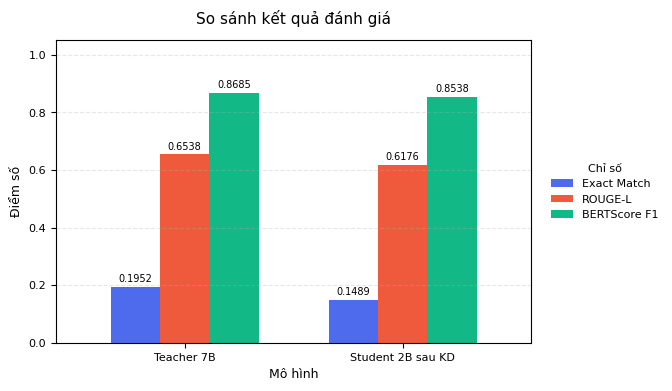

Đã lưu biểu đồ: /content/drive/MyDrive/TtI/Vi-VQA-End-to-End/results/evaluation_teacher_student_small.png


In [9]:
import matplotlib.pyplot as plt

metrics = [
    "Exact Match",
    "ROUGE-L",
    "BERTScore F1",
]

fig, ax = plt.subplots(figsize=(7.2, 4.2))

table.set_index("Model")[metrics].plot(
    kind="bar",
    ax=ax,
    width=0.68,
    color=[
        "#4F6BED",
        "#F05A3C",
        "#12B886",
    ],
)

ax.set_title(
    "So sánh kết quả đánh giá",
    fontsize=11,
    pad=12,
)

ax.set_xlabel("Mô hình", fontsize=9)
ax.set_ylabel("Điểm số", fontsize=9)
ax.set_ylim(0, 1.05)
ax.tick_params(axis="both", labelsize=8)
ax.grid(axis="y", linestyle="--", alpha=0.3)

# Chú thích đặt bên phải, xếp dọc
ax.legend(
    title="Chỉ số",
    fontsize=8,
    title_fontsize=8,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    ncol=1,
    frameon=False,
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f",
        padding=2,
        fontsize=7,
    )

plt.xticks(rotation=0)
plt.subplots_adjust(
    left=0.12,
    right=0.78,
    bottom=0.16,
    top=0.88,
)

chart_path = RESULTS_DIR / "evaluation_teacher_student_small.png"

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
print("Đã lưu biểu đồ:", chart_path)